In [1]:
from torchvision import datasets, transforms

transform = transforms.Compose([transforms.ToTensor()])
train_data = datasets.CIFAR10(root="~/.cache/", transform=transform, train=True, download=True)
test_data = datasets.CIFAR10(root="~/.cache/", transform=transform, train=False)
print(train_data[0][0].shape)
print(test_data[0][0].dtype)

Files already downloaded and verified
torch.Size([3, 32, 32])
torch.float32


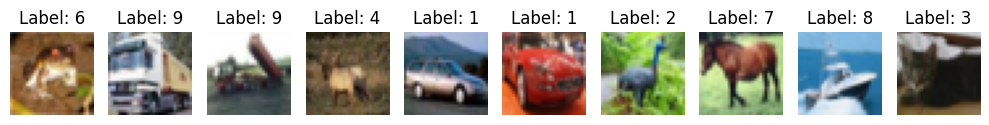

In [2]:
import matplotlib.pyplot as plt

# 遍历前10张图片
fig, axes = plt.subplots(1, 10, figsize=(10, 2))  # 1行10列的子图
for i in range(10):
    image, label = train_data[i]
    ax = axes[i]  # 获取当前子图
    ax.imshow(image.permute(1, 2, 0))
    ax.set_title(f'Label: {label}')  # 显示标签
    ax.axis('off')  # 关闭坐标轴

plt.tight_layout()  # 自动调整子图间的间距
plt.show()

In [3]:
import torch
import torch.nn as nn
import torch.nn.functional as F

from quantizer import VectorQuantizer
from vqvae import VQVAE
from model import Encoder, Decoder

quantizer = VectorQuantizer(n_e=512, e_dim=16)
vqvae = VQVAE(Encoder(), Decoder(), quantizer)

x: torch.Tensor = train_data[0][0]
x = x.unsqueeze(0)  # 添加batch维度

x_q, indices, vq_loss, codebook_usage = vqvae(x) 
print(x_q.shape)
print(indices.shape) # use 64 tokens to encode one image
print(codebook_usage.shape)

z_q = vqvae.encode(x)
print(z_q.shape)

torch.Size([1, 3, 32, 32])
torch.Size([1, 128])
torch.Size([512])
torch.Size([1, 32, 8, 8])


In [ ]:
from lpips import LPIPS

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

lipis_model = LPIPS().eval().to(device)
quantizer = VectorQuantizer(n_e=256, e_dim=16, norm_weight=False)
encoder = Encoder()
decoder = Decoder()
vqvae = VQVAE(encoder, decoder, quantizer).to(device)

dataloader = torch.utils.data.DataLoader(train_data, batch_size=512, shuffle=True, num_workers=8)
optimizer = torch.optim.Adam(vqvae.parameters(), lr=1e-3)
epochs = 50


vqvae.train()
for epoch in range(epochs):
    for img, _ in dataloader:
        img = img.to(device)

        x_q, _, q_loss, usage = vqvae(img)
        entropy_loss = torch.sum(usage * torch.log(usage + 1e-6)) # 直接对分布熵做约束，效果比L2 norm好多了...
        perception_loss = lipis_model(x_q, img).mean()
        loss = F.mse_loss(x_q, img) + q_loss + perception_loss + 0.01 * entropy_loss

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
    if epoch == 0 or (epoch + 1) % 5 == 0:
        print(f"Epoch {epoch + 1}/{epochs}, Loss: {loss.item():.4f}")



loaded pretrained LPIPS loss from /public/hpk/denoising-diffusion-pytorch/cache/vgg.pth
Epoch 1/50, Loss: 0.6254
Epoch 5/50, Loss: 0.2711
Epoch 10/50, Loss: 0.1919
Epoch 15/50, Loss: 0.1647
Epoch 20/50, Loss: 0.1388
Epoch 25/50, Loss: 0.1323
Epoch 30/50, Loss: 0.1377
Epoch 35/50, Loss: 0.1286
Epoch 40/50, Loss: 0.1278
Epoch 45/50, Loss: 0.1270
Epoch 50/50, Loss: 0.1230


[143 188 143 157 160 157 160 186 231 116 218 157  26 186 205 155  56 149
 160 116 187 188  53  72 248 181 147  86  45 200 160 149 132  75 105 209
  59  30  46 158 153 216 224  62  46 130 218 145 132   4 243  79  32   4
 147  28 170 164 205  10 195 181 250 222 120  76  80  66  80 155 122  76
 125  97  56 112 205 214  41  79 161 127 199 158  59  10 154  76  77 129
  77  81 255   4 106  76 124  81  31 159  45 232 255 152  24  81 195 130
  14  22 137 184 136  75 101 123 218 152 136 164 208 130 124 173 139 184
  57  75]


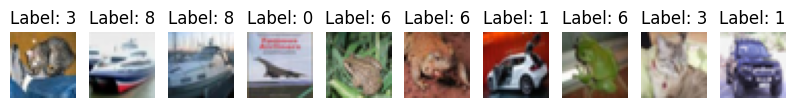

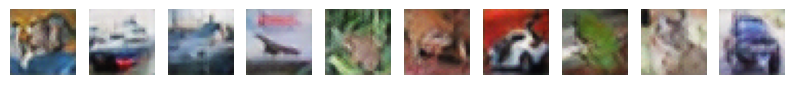

In [10]:
# 遍历前10张图片
x = torch.vstack([test_data[i][0].unsqueeze(0) for i in range(10)]).to(device)

x_q, ids, vq_loss, _ = vqvae(x)
x_q = x_q.cpu().detach()
x_p = vqvae.decode(vqvae.encode(x)).cpu().detach()

print(ids[0].cpu().numpy())

fig, axes = plt.subplots(1, 10, figsize=(10, 2))  # 1行10列的子图
for i in range(10):
    image, label = test_data[i]
    ax = axes[i]  # 获取当前子图
    ax.imshow(image.permute(1, 2, 0))
    ax.set_title(f'Label: {label}')  # 显示标签
    ax.axis('off')  # 关闭坐标轴

fig, axes = plt.subplots(1, 10, figsize=(10, 2))  # 1行10列的子图
for i in range(10):
    image, label = x_p[i], test_data[i][1]
    ax = axes[i]  # 获取当前子图
    ax.imshow(image.permute(1, 2, 0))
    ax.axis('off')  # 关闭坐标轴

tensor(1.1269e-05)
tensor(74)


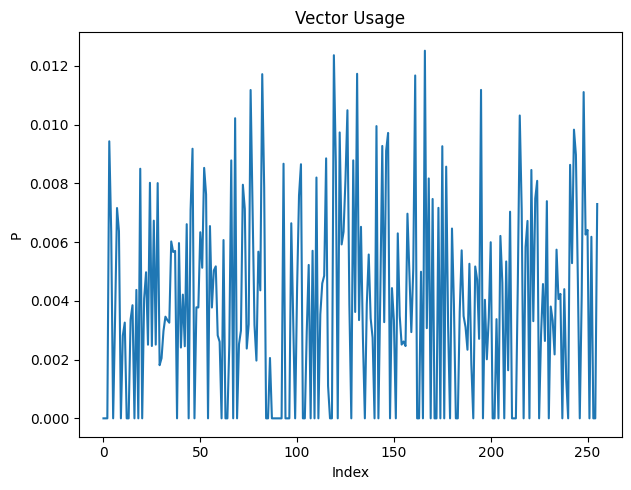

In [11]:
test_loader = torch.utils.data.DataLoader(test_data, batch_size=512, shuffle=False, num_workers=4)

vqvae.eval()
usage = 0
for img, _ in test_loader:
    img = img.to(device)

    _, _, _, u = vqvae(img)
    usage += u.cpu() * len(img)

usage /= len(test_data)

print(usage.var())
print(torch.sum(usage == 0.0))
plt.figure(figsize=(12, 5))

# 折线图
plt.subplot(1, 2, 1)
plt.plot(usage)
plt.title('Vector Usage')
plt.xlabel('Index')
plt.ylabel('P')


plt.tight_layout()
plt.show()